In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
class LDA:
    def __init__(self, n_components):
        self.n_components = n_components
        self.W = None  # Store the eigenvector computed

    def fit(self, X, y):
        n_features = X.shape[1]  # 150, 4 (iris dataset)
        class_labels = np.unique(y)

        # Calculate S_W, S_B
        mean_overall = np.mean(X, axis=0)
        S_W = np.zeros((n_features, n_features))  # 4, 4
        S_B = np.zeros((n_features, n_features))  # 4, 4

        for c in class_labels:
            # Filter X for class c
            X_c = X[y == c]

            # Calculate the mean vector for class c
            mean_c = np.mean(X_c, axis=0)

            # Calculate within-class scatter for class c
            # (4, n_c) * (n_c, 4) = (4, 4)
            S_W += (X_c - mean_c).T.dot((X_c - mean_c))

            # number of samples in classe C
            n_c = X_c.shape[0]

            # Difference between the overall mean and the mean of class c --> between-class scatter
            # (4, 1) * (1, 4) = (4, 4)
            mean_diff = (mean_c - mean_overall).reshape(n_features, 1)  # (4, 1)
            S_B += n_c * (mean_diff).dot(mean_diff.T)

        # Determine SW^-1 * SB
        A = np.linalg.inv(S_W).dot(S_B)

        # Get the eigenvalues and eigenvectors of (SW^-1 * SB)
        eigenvalues, eigenvectors = np.linalg.eig(A)

        # Keep only the real parts of eigenvalues and eigenvectors
        eigenvalues = np.real(eigenvalues)
        eigenvectors = np.real(eigenvectors.T)

        # Sort the eigenvalues descending (high to low)
        idxs = np.argsort(np.abs(eigenvalues))[::-1]
        self.eigenvalues = np.abs(eigenvalues[idxs])
        self.eigenvectors = eigenvectors[idxs]

        # Store the first m eigenvectors as transformation matrix W
        self.W = self.eigenvectors[0 : self.n_components]

    def transform(self, X):
        return np.dot(
            X, self.W.T
        )  # Project the data into the linear discriminant vector (w) calculated

    def _get_explained_variance(self):
        return self.eigenvalues[0 : self.n_components] / np.sum(self.eigenvalues)

In [3]:
# URL to Github repository
url = "https://raw.githubusercontent.com/IngoNowitzky/LDA_Medium/main/production_line_data.csv"

# Read csv to DataFrame
data = pd.read_csv(url)

# Print first 5 lines
data.head()

,Station_1,Station_2,Station_3,Station_4,Station_5,Station_6,Station_7,Label
0,0.749080,0.919993,114.945602,0.932442,13.727151,2.903895,0.908278,Good
1,1.901429,-1.261952,104.740889,2.048815,9.016888,2.634858,3.778081,Good
2,1.463988,-0.613441,106.317961,-1.294561,14.625247,1.755185,4.307704,Good
3,1.197317,0.653123,109.033556,-2.686570,13.902569,2.466063,3.553937,Good
4,0.312037,-0.071643,110.182667,-2.449227,14.431973,1.825483,3.623181,Good


In [4]:
# Show average, min and max of numerical values
data.describe()

,Station_1,Station_2,Station_3,Station_4,Station_5,Station_6,Station_7
count,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,0.998689,-0.002472,125.000210,-0.995950,11.487429,2.505333,3.494414
std,0.577006,1.151520,14.441149,2.294479,2.027949,1.446818,2.020641
min,0.000023,-1.999978,100.000422,-4.998960,8.000205,0.000138,0.000398
25%,0.499774,-0.998176,112.549949,-2.977451,9.709597,1.242712,1.737593
50%,0.997864,0.004245,124.999161,-0.988751,11.509644,2.513874,3.492975
75%,1.498282,0.984467,137.607742,0.998488,13.253729,3.761920,5.240301
max,1.999850,1.999604,149.998607,2.999001,14.999944,4.999313,6.999449


In [5]:
# Count the number of good and bad parts
label_counts = data["Label"].value_counts()

# Display the results
print("Number of Good and Bad Parts:")
print(label_counts)

Number of Good and Bad Parts:
Label
Good    19031
Bad       969
Name: count, dtype: int64


In [6]:
# Select all bad parts
bad_parts = data[data["Label"] == "Bad"]

# Randomly select an equal number of good parts
good_parts = data[data["Label"] == "Good"].sample(n=len(bad_parts), random_state=42)

# Combine both subsets to create a balanced dataset
balanced_data = pd.concat([bad_parts, good_parts])

# Shuffle the combined dataset
balanced_data = balanced_data.sample(frac=1, random_state=42).reset_index(drop=True)

# Display the number of good and bad parts in the balanced dataset
print("Number of Good and Bad Parts in the balanced dataset:")
print(balanced_data["Label"].value_counts())

Number of Good and Bad Parts in the balanced dataset:
Label
Bad     969
Good    969
Name: count, dtype: int64


In [13]:
from sklearn.preprocessing import StandardScaler

# Separate features and labels
X = balanced_data.drop(columns=["Label"])
y = balanced_data["Label"]

# Normalize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Perform LDA
lda = LDA(n_components=1)  # Instanciate LDA object with 1 axis
lda.fit(X_scaled, y)
X_lda = lda.transform(X_scaled)  # Fit the model and project the data

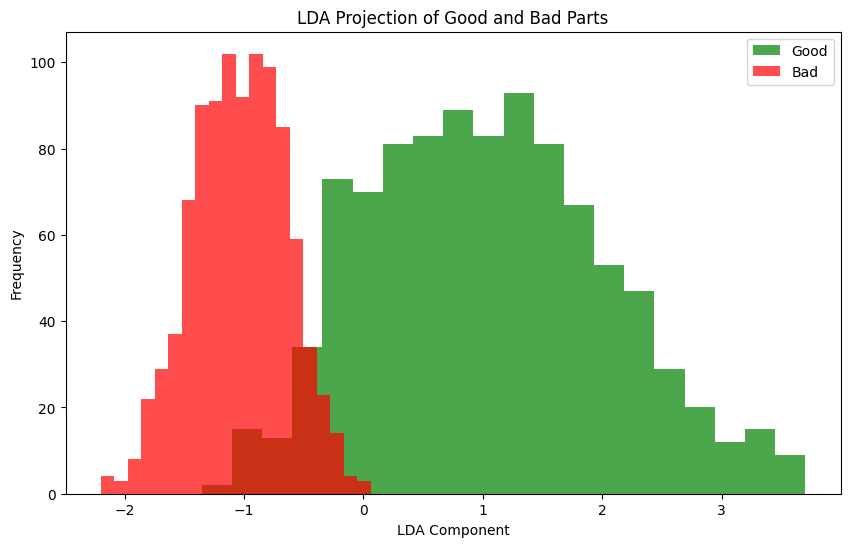

Feature Contributions to LDA Component:
     Feature  LDA Coefficient
3  Station_4         0.671635
6  Station_7         0.485592
5  Station_6         0.049462
0  Station_1         0.008391
4  Station_5        -0.004788
2  Station_3        -0.007926
1  Station_2        -0.557230


In [14]:
# Plot the LDA projection
plt.figure(figsize=(10, 6))
plt.hist(X_lda[y == "Good"], bins=20, alpha=0.7, label="Good", color="green")
plt.hist(X_lda[y == "Bad"], bins=20, alpha=0.7, label="Bad", color="red")
plt.title("LDA Projection of Good and Bad Parts")
plt.xlabel("LDA Component")
plt.ylabel("Frequency")
plt.legend()
plt.show()

# Examine feature contributions to the LDA component
feature_importance = pd.DataFrame({"Feature": X.columns, "LDA Coefficient": lda.W[0]})
feature_importance = feature_importance.sort_values(
    by="LDA Coefficient", ascending=False
)

# Display feature importance
print("Feature Contributions to LDA Component:")
print(feature_importance)

In [15]:
print(f"Explained variance: {lda._get_explained_variance()}")

Explained variance: [1.]
